# 🌫️ 기상 조건으로 베이징 미세먼지(PM2.5) 농도 예측하기

**2026 파이썬 프로그래밍 · 파이썬 프로젝트 수행하기 (선형회귀분석을 이용한 AI 모델 만들기)**

| 구분 | 내용 |
|---|---|
| 학번 / 이름 | 2124 조현수 |
| 데이터 | UCI Machine Learning Repository - Beijing PM2.5 (#381) |
| 모델 | 선형회귀 (scikit-learn `LinearRegression`) |
| 웹페이지 | Streamlit (`app.py`) |

### 목차
1. 주제 선정 이유
2. 인공지능 모델 소개
3. 데이터 불러오기
4. 모델 만들기 (조건1 ~ 조건5)
5. 웹 페이지 구현 설명
6. 마무리

## 1. 주제 선정 이유

겨울과 봄이 되면 날씨 예보보다 미세먼지 예보를 먼저 확인하는 날이 많다. 등굣길에 마스크를 챙길지, 체육 수업을 운동장에서 할지 같은 일상적인 결정이 미세먼지 농도에 따라 달라진다. 뉴스에서 우리나라 미세먼지가 중국의 영향을 받는다는 이야기를 자주 들어서, 중국의 수도인 베이징의 미세먼지는 어떤 날씨일 때 높아지는지 궁금해졌다.

마침 UCI 머신러닝 저장소에 베이징 미국 대사관이 2010년부터 2014년까지 1시간마다 측정한 PM2.5 농도와 기상 자료가 공개되어 있었다. 기온, 이슬점, 기압, 풍속 같은 날씨 정보만으로 미세먼지 농도를 어느 정도까지 예측할 수 있는지 직접 확인해 보고 싶어서 이 주제를 골랐다. 또 이 데이터에는 측정되지 않아 비어 있는 값(결측치)이 2,000개 넘게 들어 있어서, 수업 시간에 배운 결측치 처리를 실제 데이터에 적용해 볼 수 있다는 점도 이 주제를 선택한 이유다.

## 2. 인공지능 모델 소개

이 프로젝트에서는 **선형회귀(Linear Regression)** 모델을 사용했다. 선형회귀는 독립변수와 종속변수 사이의 관계를 직선(독립변수가 여러 개이면 평면) 형태의 식으로 나타내는 모델이다. 식은 다음과 같은 꼴이다.

$$\hat{y} = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b$$

여기서 $w$는 각 변수가 결과에 얼마나 영향을 주는지 나타내는 **가중치(계수)**이고, $b$는 **절편**이다. 학습 과정에서는 실제값과 예측값의 차이를 제곱해서 모두 더한 값이 가장 작아지도록 $w$와 $b$를 찾는다(최소제곱법).

이번 프로젝트에서는 이슬점(DEWP), 기온(TEMP), 기압(PRES), 누적 풍속(Iws), 누적 강설 시간(Is), 누적 강수 시간(Ir) 6개를 독립변수로, PM2.5 농도를 종속변수로 정했다. 선형회귀는 계산이 빠르고, 학습이 끝난 뒤 계수만 보면 어떤 변수가 미세먼지를 높이고 어떤 변수가 낮추는지 바로 해석할 수 있다는 장점이 있다. 반대로 변수 사이의 관계가 직선이 아닐 때는 예측이 잘 맞지 않는다는 한계가 있다. 구현에는 scikit-learn 라이브러리의 `LinearRegression` 클래스를 사용했다.

## 3. 데이터 불러오기

| 열 이름 | 의미 | 단위 |
|---|---|---|
| year, month, day, hour | 측정 날짜와 시간 | - |
| **pm2.5** | 초미세먼지 농도 (**종속변수**) | ㎍/㎥ |
| DEWP | 이슬점 (수증기가 이슬로 맺히는 온도, 기온과 가까울수록 습함) | ℃ |
| TEMP | 기온 | ℃ |
| PRES | 기압 | hPa |
| cbwd | 풍향 (NE, NW, SE, cv=고요) | - |
| Iws | 누적 풍속 (같은 방향 바람이 이어진 만큼 쌓인 풍속) | m/s |
| Is | 누적 강설 시간 | 시간 |
| Ir | 누적 강수 시간 | 시간 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# UCI 저장소에서 데이터를 바로 불러온다. (구글 코랩에서도 그대로 실행 가능)
url = "https://archive.ics.uci.edu/static/public/381/data.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(43824, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


## 4. 모델 만들기

### [조건1] 결측치 확인 및 처리

**코드 설명**
- `df.isnull()`은 값이 비어 있으면 `True`, 있으면 `False`인 표를 만든다. 여기에 `.sum()`을 붙이면 `True`가 1로 계산되어 열마다 결측치 개수가 나온다.
- 확인해 보면 결측치는 **종속변수인 `pm2.5` 열에만** 있다. 측정 장비가 값을 기록하지 못한 시간이다.
- 처리 방법은 **삭제**를 골랐다. `pm2.5`는 모델이 맞혀야 하는 정답이기 때문에, 평균값 같은 값으로 채우면 모델이 실제로 측정된 적 없는 가짜 정답을 배우게 된다. 비어 있는 행은 전체의 약 4.7%뿐이고 남은 데이터도 4만 개가 넘어서, 삭제해도 학습에 충분하다.
- `df.dropna(subset=["pm2.5"])`는 `pm2.5`가 비어 있는 행만 지운다. 지운 뒤 다시 `isnull().sum()`으로 결측치가 0개인지 확인했다.

In [3]:
# 1) 결측치 확인
print("전체 행 수 :", len(df))
print(df.isnull().sum())
print("pm2.5 결측 비율 : {:.2f}%".format(df["pm2.5"].isnull().mean() * 100))

전체 행 수 : 43824
No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64
pm2.5 결측 비율 : 4.72%


In [4]:
# 2) 결측치 처리 : 정답(pm2.5)이 없는 행은 학습에 쓸 수 없으므로 삭제
df = df.dropna(subset=["pm2.5"])

print("삭제 후 행 수 :", len(df))
print("남은 결측치 개수 :", df.isnull().sum().sum())

삭제 후 행 수 : 41757
남은 결측치 개수 : 0


### [조건2] 상관계수 구하기

**코드 설명**
- `df.corr(numeric_only=True)`는 숫자로 된 열끼리 모두 짝지어 피어슨 상관계수를 계산한다. 풍향(`cbwd`)은 문자라서 `numeric_only=True`로 제외했고, 단순 번호인 `No` 열도 뺐다.
- 상관계수는 -1에서 1 사이의 값이다. 1에 가까우면 함께 커지고, -1에 가까우면 하나가 커질 때 다른 하나는 작아지며, 0에 가까우면 직선 관계가 거의 없다.
- 우리가 궁금한 것은 `pm2.5`와 다른 변수의 관계이므로 `corr["pm2.5"]`만 꺼냈다. 그리고 `key=abs`로 **절댓값이 큰 순서**(관계가 강한 순서)로 정렬했다.
- 전체 상관관계는 `plt.imshow`로 히트맵을 그려 색으로 한눈에 볼 수 있게 했다.

In [5]:
corr = df.drop(columns=["No"]).corr(numeric_only=True)

# pm2.5 와의 상관계수만 꺼내서 절댓값이 큰 순서로 정렬
pm_corr = corr["pm2.5"].drop("pm2.5").sort_values(key=abs, ascending=False)
print(pm_corr.round(3))

Iws     -0.248
DEWP     0.171
TEMP    -0.091
day      0.083
Ir      -0.051
PRES    -0.047
month   -0.024
hour    -0.023
Is       0.019
year    -0.015
Name: pm2.5, dtype: float64


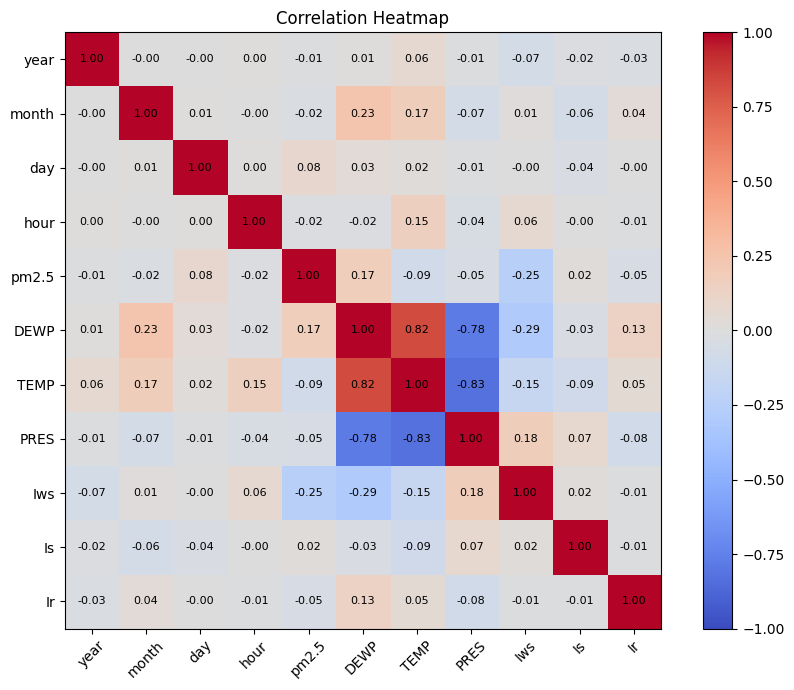

In [6]:
# 상관계수 히트맵
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**결과 해석**
- `pm2.5`와 상관계수의 절댓값이 가장 큰 변수는 **누적 풍속 `Iws`(-0.248)**, 그다음이 **이슬점 `DEWP`(0.171)**이다.
- `Iws`가 음수라는 것은 바람이 오래, 강하게 불수록 미세먼지가 줄어든다는 뜻이고, `DEWP`가 양수라는 것은 공기가 습할수록 미세먼지가 늘어난다는 뜻이다.
- 기온(-0.091), 강수 시간(-0.051), 기압(-0.047)은 관계가 더 약하다. 전체적으로 0.3을 넘는 변수가 없어서, **날씨 하나만으로는 미세먼지를 강하게 설명하지 못한다**는 것을 미리 짐작할 수 있다.
- `year`, `month`, `day`, `hour`는 날씨가 아니라 측정 시각이므로 독립변수에서 제외했다.

### [조건3] 상관계수가 높은 독립변수와 종속변수 시각화

**코드 설명**
- 조건2에서 상관계수 절댓값이 가장 높았던 두 변수 `Iws`, `DEWP`를 골라 `pm2.5`와의 산점도를 그렸다.
- 점이 4만 개가 넘어서 겹치면 분포가 잘 안 보이기 때문에 `alpha=0.1`로 점을 반투명하게 하고 `s=5`로 크기를 줄였다.
- `np.polyfit(x, y, 1)`은 점들에 가장 잘 맞는 1차식(직선)의 기울기와 절편을 구해 준다. 이 직선을 빨간색으로 겹쳐 그려서 전체 경향을 확인했다.

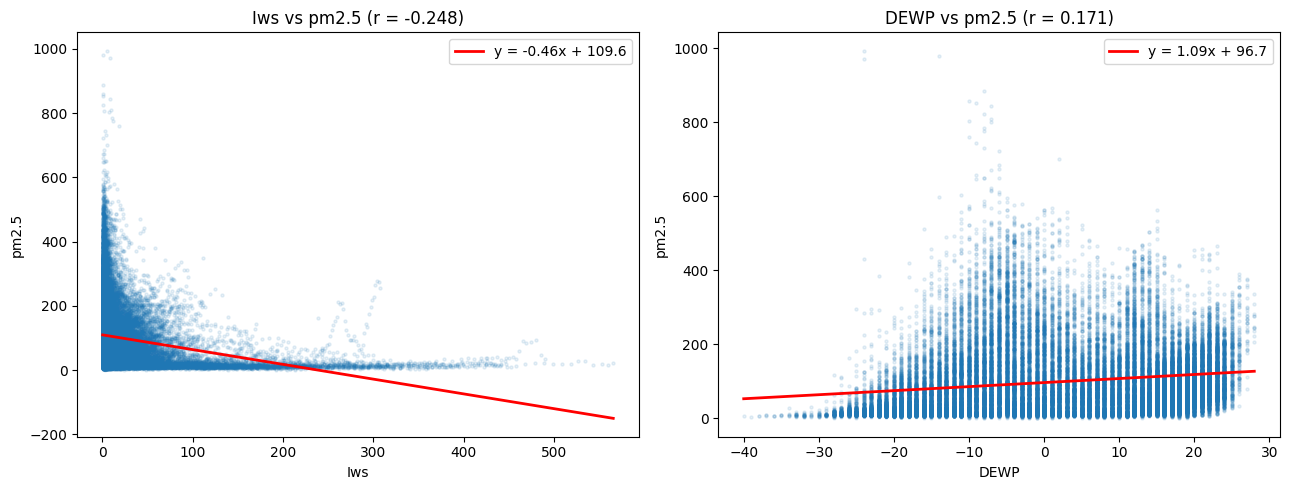

In [7]:
top_features = ["Iws", "DEWP"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col in zip(axes, top_features):
    x = df[col]
    y = df["pm2.5"]
    ax.scatter(x, y, s=5, alpha=0.1)

    # 1차 추세선 (기울기 a, 절편 b)
    a, b = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, a * xs + b, color="red", linewidth=2, label=f"y = {a:.2f}x + {b:.1f}")

    ax.set_xlabel(col)
    ax.set_ylabel("pm2.5")
    ax.set_title(f"{col} vs pm2.5 (r = {pm_corr[col]:.3f})")
    ax.legend()

plt.tight_layout()
plt.show()

**그래프 분석**
- **Iws(누적 풍속) - pm2.5** : 누적 풍속이 0~50 정도로 작을 때는 미세먼지가 0부터 1,000 가까이까지 아주 넓게 퍼져 있다. 반면 누적 풍속이 100을 넘어가면 점들이 대부분 바닥(낮은 농도)에 붙어 있다. 즉 **바람이 오래, 강하게 불면 미세먼지가 흩어져서 거의 항상 낮아진다.** 다만 그래프 모양이 직선이 아니라 'L자'에 가까워서, 직선으로 나타낸 상관계수는 -0.248로 작게 나왔다. 빨간 추세선은 누적 풍속 약 220 이후로 0 아래로 내려가는데, 실제 농도는 0보다 작아질 수 없다. 이것만 봐도 이 관계를 직선 하나로 나타내는 데는 한계가 있다는 것을 알 수 있다.
- **DEWP(이슬점) - pm2.5** : 이슬점이 낮은(건조한) 쪽에서는 미세먼지가 대체로 낮게 모여 있고, 이슬점이 높아질수록 높은 농도의 점이 많아지면서 위쪽으로 넓게 퍼진다. 추세선도 오른쪽 위로 올라간다. 습한 날에는 공기가 정체되고 미세먼지 입자가 수분을 머금어 커지기 때문으로 보인다. 하지만 같은 이슬점에서도 값이 위아래로 크게 퍼져 있어서 관계는 약한 편이다.
- 두 그래프 모두 같은 x값에서 y값이 넓게 흩어져 있다. 따라서 이 변수들로 만든 **선형회귀 모델의 정확도는 높지 않을 것**으로 예상된다.

### [조건4] 인공지능 모델 학습

**코드 설명**
- 독립변수 `X`는 날씨 변수 6개(`DEWP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`)이고, 종속변수 `y`는 `pm2.5`이다. 풍향 `cbwd`는 문자 데이터라 이번에는 사용하지 않았다.
- `train_test_split`으로 데이터를 **학습용 80%, 검증용 20%**로 나눴다. 모델이 한 번도 보지 못한 데이터로 성능을 평가해야 실제로 예측을 잘하는지 알 수 있기 때문이다. `random_state=42`로 고정해서 실행할 때마다 같은 결과가 나오게 했다.
- `LinearRegression()`으로 모델을 만들고 `fit(X_train, y_train)`으로 학습시켰다. 학습이 끝나면 `coef_`에 각 변수의 계수가, `intercept_`에 절편이 저장된다.

In [8]:
features = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
X = df[features]
y = df["pm2.5"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("학습 데이터 :", X_train.shape, " 검증 데이터 :", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

coef = pd.Series(model.coef_, index=features)
print("\n[계수]")
print(coef.round(3))
print("\n[절편] {:.2f}".format(model.intercept_))

학습 데이터 : (33405, 6)  검증 데이터 : (8352, 6)

[계수]
DEWP    4.300
TEMP   -6.018
PRES   -1.457
Iws    -0.260
Is     -2.343
Ir     -7.277
dtype: float64

[절편] 1654.60


**학습 결과 해석** (다른 변수는 그대로라고 가정)
- **DEWP +4.30** : 이슬점이 1℃ 오르면 미세먼지가 약 4.3㎍/㎥ 늘어난다.
- **TEMP -6.02** : 기온이 1℃ 오르면 약 6.0㎍/㎥ 줄어든다. 이슬점의 계수와 같이 보면, 기온과 이슬점이 가까운 **습한 날**일수록 미세먼지가 높다는 뜻이 된다.
- **Iws -0.26** : 누적 풍속이 100 늘면 약 26㎍/㎥ 줄어든다. 바람이 미세먼지를 흩어 놓는다.
- **Ir -7.28, Is -2.34** : 비나 눈이 오래 내릴수록 낮아진다. 빗방울이 공기 중의 먼지를 씻어 내리기 때문이다.
- **PRES -1.46** : 기압이 높을수록 조금 낮아진다.

### [조건5] MSE, R2 검증

**코드 설명**
- 학습에 쓰지 않은 검증 데이터 `X_test`를 `model.predict()`에 넣어 예측값 `y_pred`를 만들었다.
- `mean_squared_error(y_test, y_pred)`는 **MSE(평균제곱오차)**로, (실제값 - 예측값)²의 평균이다. 0에 가까울수록 좋다. 단위가 제곱이라 크기를 실감하기 어려워서, 제곱근을 씌운 RMSE도 함께 구했다.
- `r2_score(y_test, y_pred)`는 **R²(결정계수)**로, 종속변수가 변하는 정도 중에서 모델이 설명하는 비율이다. 1에 가까울수록 좋다.
- 학습 데이터의 R²(`model.score`)도 함께 비교해서 과대적합 여부를 확인했다.
- 마지막으로 실제값과 예측값을 산점도로 그렸다. 예측이 완벽하면 모든 점이 빨간 점선(y = x) 위에 놓인다.

In [9]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE  : {:.2f}".format(mse))
print("RMSE : {:.2f}".format(rmse))
print("R2   : {:.4f}".format(r2))
print("학습 데이터 R2 : {:.4f}".format(model.score(X_train, y_train)))
print("pm2.5 평균 : {:.1f}".format(y.mean()))

MSE  : 6765.37
RMSE : 82.25
R2   : 0.2322
학습 데이터 R2 : 0.2371
pm2.5 평균 : 98.6


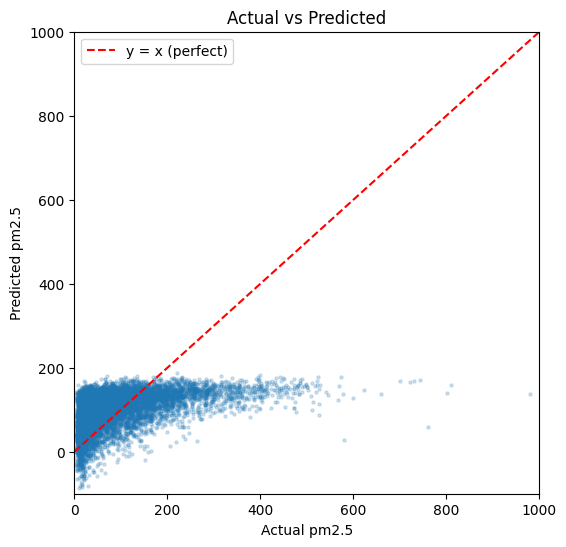

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=5, alpha=0.2)
plt.plot([0, 1000], [0, 1000], "r--", label="y = x (perfect)")
plt.xlim(0, 1000)
plt.ylim(-100, 1000)
plt.xlabel("Actual pm2.5")
plt.ylabel("Predicted pm2.5")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

**MSE, R2 값에 따른 모델 성능 분석**
- **R² = 0.232** : 미세먼지 농도가 변하는 정도 가운데 약 23%만 이 모델이 설명한다는 뜻이다. 나머지 77%는 이 모델에 넣은 날씨 변수로 설명하지 못한다. **성능이 좋은 모델이라고 보기는 어렵다.**
- **MSE = 6765.37, RMSE = 82.25** : 예측이 평균적으로 약 82㎍/㎥ 정도 빗나간다는 뜻이다. PM2.5의 평균이 약 98.6㎍/㎥인 것과 비교하면 오차가 꽤 크다. 예를 들어 '보통(16~35)'인 날과 '매우나쁨(76 이상)'인 날을 정확히 가려내기는 힘들다.
- 실제값-예측값 그래프를 보면 예측값이 대부분 0~200 사이에 몰려 있다. 실제 농도가 300 이상인 심한 날도 모델은 낮게 예측한다. 실제 농도가 아주 낮은 날에는 예측값이 음수로 나오기도 한다. 직선 식에는 '0 이상'이라는 제한이 없기 때문이다(웹페이지에서는 0 미만을 0으로 처리했다).
- 학습 데이터의 R²(0.237)와 검증 데이터의 R²(0.232)가 거의 같다. 따라서 학습 데이터만 외운 **과대적합은 아니다.** 오히려 모델이 너무 단순해서 데이터의 패턴을 다 잡지 못한 **과소적합**에 가깝다.

**성능이 낮은 이유와 개선 방법**
1. 조건3의 그래프에서 봤듯이 풍속과 미세먼지의 관계는 직선이 아니라 'L자' 곡선에 가깝다. 그래서 직선만 그릴 수 있는 선형회귀로는 한계가 있다.
2. 미세먼지는 날씨뿐 아니라 난방·자동차·공장 같은 **배출원**, **바로 전 시간의 농도**, 다른 지역에서 날아오는 먼지에도 큰 영향을 받는다. 이런 정보가 데이터에 없다.
3. 문자 데이터인 풍향(`cbwd`)을 사용하지 않았다.

→ 풍향을 원-핫 인코딩으로 숫자로 바꿔 추가하거나, 직전 시간의 농도를 독립변수로 넣거나, 곡선 관계도 학습하는 랜덤포레스트 같은 모델을 쓰면 성능을 높일 수 있을 것이다.

## 5. 웹 페이지 구현 설명 (`app.py`)

웹페이지는 **Streamlit**으로 만들었다. `app.py`는 노트북과 똑같은 방법(결측치 삭제 → 8:2 분할 → 선형회귀 학습)으로 모델을 학습한다. `@st.cache_resource`를 붙여서 처음 한 번만 학습하고, 그 뒤에는 학습한 모델을 재사용한다. 자세한 설명은 `app.py`의 주석에도 적어 두었다.

### [조건1] 독립변수 값 입력받는 코드
```python
col1, col2 = st.columns(2)
with col1:
    temp = st.number_input("기온 TEMP (℃)", min_value=-20.0, max_value=45.0, value=14.0, step=1.0)
    dewp = st.number_input("이슬점 DEWP (℃)", min_value=-40.0, max_value=30.0, value=2.0, step=1.0)
    pres = st.number_input("기압 PRES (hPa)", min_value=990.0, max_value=1050.0, value=1016.0, step=1.0)
with col2:
    iws = st.number_input("누적 풍속 Iws (m/s)", min_value=0.0, max_value=570.0, value=5.4, step=1.0)
    is_snow = st.number_input("누적 강설 시간 Is (시간)", min_value=0, max_value=30, value=0, step=1)
    ir_rain = st.number_input("누적 강수 시간 Ir (시간)", min_value=0, max_value=40, value=0, step=1)
```
- `st.number_input`은 숫자만 입력할 수 있는 입력창을 만들고, 사용자가 입력한 값을 변수에 저장한다.
- `min_value`, `max_value`는 학습 데이터에 실제로 있던 범위로 정했다. 기압 0hPa처럼 말이 안 되는 값을 넣을 수 없게 하기 위해서다.
- 기본값(`value`)은 학습 데이터의 중앙값, 즉 가장 흔한 날씨로 정했다.
- `st.columns(2)`로 화면을 두 칸으로 나눠 입력창 6개를 보기 좋게 배치했다.

### [조건2] 예측 결과 구현 코드
```python
input_data = pd.DataFrame([[dewp, temp, pres, iws, is_snow, ir_rain]], columns=FEATURES)
prediction = max(0.0, float(model.predict(input_data)[0]))
grade, emoji, show_box = pm25_grade(prediction)

c1, c2 = st.columns(2)
c1.metric("예측 PM2.5 농도", f"{prediction:.1f} ㎍/㎥")
c2.metric("예보 등급", f"{emoji} {grade}")
show_box(f"이 날씨에서 예상되는 미세먼지 등급은 **{grade}** 입니다.")
```
- 입력받은 6개 값을 학습할 때와 **같은 열 이름과 순서**의 DataFrame으로 만들어 `model.predict()`에 넣는다.
- `predict()`는 결과를 배열로 돌려주므로 `[0]`으로 첫 번째 값을 꺼낸다. 농도는 음수가 될 수 없으므로 `max(0.0, 값)`으로 0 미만은 0으로 바꾼다.
- `pm25_grade()` 함수는 예측값을 우리나라 PM2.5 예보 등급(좋음 0~15 / 보통 16~35 / 나쁨 36~75 / 매우나쁨 76 이상)으로 바꿔 준다.
- `st.metric`으로 숫자를 크게 보여 주고, 등급에 따라 초록·파랑·노랑·빨강 상자(`st.success`, `st.info`, `st.warning`, `st.error`)로 안내 문구를 출력한다.

### [조건3] 인공지능 분석 버튼 코드
```python
if st.button("🤖 인공지능 분석", type="primary"):
    # 이 안에 [조건2]의 예측 코드가 들어 있다
    ...
else:
    st.info("날씨 정보를 입력하고 🤖 인공지능 분석 버튼을 눌러 주세요.")
```
- `st.button()`은 화면에 버튼을 만들고, **버튼이 눌린 순간에만 `True`**를 돌려준다.
- 그래서 예측 코드를 `if` 문 안에 넣으면, 값을 입력하는 동안에는 아무 일도 일어나지 않다가 버튼을 누르는 순간 인공지능이 분석해서 결과를 보여 준다.
- 버튼을 누르기 전에는 `else` 부분이 실행되어 사용 방법을 안내한다. `type="primary"`는 버튼을 눈에 띄는 색으로 바꾸는 옵션이다.

## 6. 마무리

날씨 정보 6개로 베이징의 미세먼지 농도를 예측하는 선형회귀 모델을 만들고, Streamlit 웹페이지로 누구나 값을 넣어 볼 수 있게 했다. 모델의 R²는 0.23으로 높지 않았다. 하지만 바람이 강하고 오래 불수록, 비가 올수록, 공기가 건조할수록 미세먼지가 낮아진다는 경향은 계수와 그래프로 분명하게 확인할 수 있었다. 이번 프로젝트를 하면서 상관계수가 낮다고 관계가 없는 것이 아니라 관계가 직선이 아닐 수도 있다는 점을 알게 되었다. 다음에는 풍향과 직전 시간의 농도를 추가하고 다른 모델과도 비교해 보고 싶다.